# PSX: Classification, Return Regression and Trading Experiments

This notebook contains only the data preparation and modelling components required for the classification, regression and trading experiment stage. It does not rerun the separate Stage 1 audit report. Feature construction and train-only screening are included only as modelling inputs. Validation is used for model selection; final test data are held out.

**Exports:** `PSX_STAGE_1_DATA_QUALITY_COMPUTATIONAL_USABILITY_FINAL.xlsx` (requested filename).

In [1]:
%pip -q install numpy pandas scipy statsmodels scikit-learn yfinance openpyxl matplotlib


In [ ]:
# =====================================================================
# DATA PREPARATION — ORIGINAL 471 CANDIDATE FEATURES
# This cell retains the source notebook's candidate-feature definitions,
# indicator calculations, PSX ticker list, date range and chronological
# training split. Chronological splits are created for downstream modelling.
# =====================================================================

"""
# -*- coding: utf-8 -*-

PSX FULL EXPERIMENT — CLASSIFICATION, REGRESSION AND TRADING
-----------------------------------
- Uses the existing, exact 471 candidate feature definitions.
- Uses only Direction_5D and Future_Return_5D as validation targets.
- Creates 471 candidate features for modelling and backtesting.
- All empirical feature-validation decisions are based on chronological TRAIN data only.
- Stage 1 produces PASS / FAIL / REVIEW decisions and threshold sensitivity results.
- Excel report is written to PSX_15_Stage_Feature_Validation_Report.xlsx.
"""
import os, sys, re, math, json, random, warnings, traceback
from pathlib import Path
import numpy as np
import pandas as pd
import yfinance as yf
from scipy.stats import spearmanr, norm, ks_2samp, rankdata
from statsmodels.stats.diagnostic import breaks_cusumolsresid
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score
warnings.filterwarnings("ignore")

# --------------------------- CONFIGURATION ---------------------------
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE); random.seed(RANDOM_STATE)
START_DATE = "2021-09-15"
END_DATE = "2026-09-15"
TARGET_HORIZON = 5
TRAIN_RATIO = 0.60
VALIDATION_RATIO = 0.20
TEST_RATIO = 0.20
PURGE_GAP = TARGET_HORIZON
MIN_DATA_ROWS = 500
MIN_OBSERVATIONS = 100
MAX_MISSING_RATE = 0.20
MIN_VARIANCE = 1e-12

MIN_STOCKS_FOR_CROSS_STOCK = 5
ROUND_TRIP_COST_RATE = 0.0020
OUTPUT_XLSX = "Stage_01_Data_Quality_Validation.xlsx"

TICKERS = [
    "MEBL.KA", "MCB.KA", "EFERT.KA", "LUCK.KA", "OGDC.KA", "SYS.KA", "EPCL.KA", "ISL.KA", "MUGHAL.KA",
    "PPL.KA", "PSO.KA", "HUBC.KA", "BAHL.KA", "FFC.KA", "ABL.KA", "HBL.KA", "POL.KA", "APL.KA", "DGKC.KA",
    "FCCL.KA", "KEL.KA", "AIRLINK.KA", "AGP.KA", "TRG.KA", "ABOT.KA", "ACPL.KA", "AGHA.KA", "AGIL.KA", "ATRL.KA",
    "CNERGY.KA", "NRL.KA", "PRL.KA", "SEARL.KA", "MTL.KA"
]

TARGETS = {
    "Classification": "Direction_5D",
    "Regression": "Future_Return_5D",
     "Trading": "Trading_Signal_5D"
}

STAGE_METHODS = [
 (1,"Data Quality and Computational Usability","Missing rate <= 0.20; finite usable observations >= 100; variance > 1e-12; at least two unique values","Allows limited natural missingness while excluding unusable/constant features; sensitivity: missing 0.10/0.20/0.30 and observations 50/100/150."),
]

def clean_numeric(s):
    return pd.to_numeric(s, errors="coerce")

def safe_spearman(x, y, min_n=60):
    z = pd.concat([pd.Series(x).reset_index(drop=True), pd.Series(y).reset_index(drop=True)], axis=1)
    z = z.replace([np.inf, -np.inf], np.nan).dropna()
    if len(z) < min_n or z.iloc[:,0].nunique() < 2 or z.iloc[:,1].nunique() < 2:
        return np.nan
    try: return float(spearmanr(z.iloc[:,0], z.iloc[:,1]).statistic)
    except Exception: return np.nan

def status_from(value, comparator, threshold, assessable=True):
    if not assessable or pd.isna(value): return "REVIEW"
    ok = (value <= threshold) if comparator == "<=" else (value >= threshold)
    return "PASS" if bool(ok) else "FAIL"

def safe_sheet(s):
    return re.sub(r"[\\/*?:\[\]]", "_", str(s))[:31]

def split_train_only(df):
    """Create chronological partitions with a five-observation purge gap; validation uses TRAIN only."""
    n=len(df); a=int(n*TRAIN_RATIO); b=int(n*(TRAIN_RATIO+VALIDATION_RATIO))
    tr_end=max(0,a-PURGE_GAP); va_start=min(n,a); va_end=max(va_start,b-PURGE_GAP); te_start=min(n,b)
    return df.iloc[:tr_end].copy(), df.iloc[va_start:va_end].copy(), df.iloc[te_start:].copy()

def block_bootstrap_indices(n, block_len, reps, rng):
    if n <= 0: return []
    block_len=max(1,min(int(block_len),n)); out=[]
    for _ in range(reps):
        ids=[]
        while len(ids)<n:
            start=int(rng.integers(0,n-block_len+1))
            ids.extend(range(start,start+block_len))
        out.append(np.asarray(ids[:n],dtype=int))
    return out

def psi_score(expected, actual, bins=10):
    a=pd.Series(expected).replace([np.inf,-np.inf],np.nan).dropna().astype(float)
    b=pd.Series(actual).replace([np.inf,-np.inf],np.nan).dropna().astype(float)
    if len(a)<50 or len(b)<50 or a.nunique()<2: return np.nan
    edges=np.unique(np.quantile(a,np.linspace(0,1,bins+1)))
    if len(edges)<3: return np.nan
    edges[0],edges[-1]=-np.inf,np.inf
    ca=np.histogram(a,bins=edges)[0]/len(a); cb=np.histogram(b,bins=edges)[0]/len(b)
    ca=np.clip(ca,1e-6,None); cb=np.clip(cb,1e-6,None)
    return float(np.sum((cb-ca)*np.log(cb/ca)))

def pt_pvalue(x, y, min_n=80):
    """Pesaran-Timmermann directional test using sign of prior feature change as forecast."""
    z=pd.DataFrame({"x":pd.Series(x).reset_index(drop=True),"y":pd.Series(y).reset_index(drop=True)})
    z=z.replace([np.inf,-np.inf],np.nan).dropna()
    if len(z)<min_n: return np.nan
    pred=(z.x.diff()>0).iloc[1:].astype(int).to_numpy()
    actual=(z.y.iloc[1:]>0).astype(int).to_numpy()
    n=len(actual)
    if n<min_n or len(np.unique(pred))<2 or len(np.unique(actual))<2: return np.nan
    p=float(actual.mean()); q=float(pred.mean()); p11=float(np.mean((pred==1)&(actual==1)))
    pstar=p*q+(1-p)*(1-q)
    variance=max(p*q*(1-p)*(1-q)/n,1e-12)
    zstat=(p11-pstar)/math.sqrt(variance)
    return float(2*(1-norm.cdf(abs(zstat))))

def adwin_count(values, delta=0.01):
    try:
        from river.drift import ADWIN
        detector=ADWIN(delta=float(delta))
        s=pd.Series(values).replace([np.inf,-np.inf],np.nan).dropna().astype(float)
        if len(s)<100: return np.nan
        med=float(s.median()); mad=float((s-med).abs().median())
        scale=1.4826*mad if mad>1e-12 else float(s.std())
        if not np.isfinite(scale) or scale<=1e-12: return np.nan
        count=0
        for v in ((s-med)/scale).to_numpy():
            detector.update(float(v))
            if detector.drift_detected: count+=1
        return int(count)
    except Exception:
        return np.nan

def structural_break_pvalue(values):
    s=pd.Series(values).replace([np.inf,-np.inf],np.nan).dropna().astype(float)
    if len(s)<100 or s.nunique()<3: return np.nan
    resid=(s-s.mean()).to_numpy()
    try: return float(breaks_cusumolsresid(resid, ddof=1)[1])
    except Exception: return np.nan

def adversarial_auc(values):
    """AUC of a one-feature early/late-period discriminator, entirely within TRAIN."""
    s=pd.Series(values).replace([np.inf,-np.inf],np.nan).dropna().astype(float).reset_index(drop=True)
    if len(s)<120 or s.nunique()<3: return np.nan
    cut=len(s)//2; y=np.r_[np.zeros(cut,dtype=int),np.ones(len(s)-cut,dtype=int)]
    try:
        auc=float(roc_auc_score(y, rankdata(s.to_numpy())))
        return max(auc,1.0-auc)
    except Exception: return np.nan

def _safe_div(a, b):
    return a / b.replace(0, np.nan)

def _rolling_zscore(s, w):
    m = s.rolling(w, min_periods=w).mean()
    sd = s.rolling(w, min_periods=w).std()
    return _safe_div(s - m, sd)

def _macd(close, fast, slow, signal=9):
    ef = close.ewm(span=fast, adjust=False, min_periods=fast).mean()
    es = close.ewm(span=slow, adjust=False, min_periods=slow).mean()
    line = ef - es
    sig = line.ewm(span=signal, adjust=False, min_periods=signal).mean()
    hist = line - sig
    return line, sig, hist

def _rsi(close, period):
    delta = close.diff()
    gain = delta.clip(lower=0).rolling(period, min_periods=period).mean()
    loss = (-delta.clip(upper=0)).rolling(period, min_periods=period).mean()
    rs = _safe_div(gain, loss)
    return 100 - 100 / (1 + rs)

def _stoch(high, low, close, period):
    ll = low.rolling(period, min_periods=period).min()
    hh = high.rolling(period, min_periods=period).max()
    k = 100 * _safe_div(close - ll, hh - ll)
    d = k.rolling(3, min_periods=3).mean()
    return k, d

# Initialize the complete candidate list of 471 feature names
# to guarantee that FEATURE_NAMES_471 is defined and matches structural requirements.
FEATURE_NAMES_471 = []
# Bollinger Bands
for w in [10, 20, 30]:
    FEATURE_NAMES_471.extend([f"BB_Lower_{w}", f"BB_Middle_{w}", f"BB_Upper_{w}", f"BB_Width_{w}", f"BB_Position_{w}"])
# Breakouts
for w in [5, 10, 20, 30, 50]:
    FEATURE_NAMES_471.extend([f"Breakout_Up_{w}D", f"Breakout_Down_{w}D", f"High_Breakout_Distance_{w}D", f"Low_Breakout_Distance_{w}D"])
# Flags
for w in [1, 3, 5, 10, 20]:
    FEATURE_NAMES_471.extend([f"Negative_Return_Flag_{w}D", f"Positive_Return_Flag_{w}D"])
# EMAs
for w in [3, 5, 7, 10, 14, 20, 30, 50, 100, 200]:
    FEATURE_NAMES_471.extend([f"EMA_{w}", f"Close_EMA_Distance_{w}", f"Close_EMA_Ratio_{w}"])
# RSI Trends
for rw in [7, 14, 21]:
    for tw in [10, 20, 50]:
        FEATURE_NAMES_471.append(f"RSI_{rw}_TrendRatio_{tw}")
# Lags
for col in ["Close", "High", "Low", "Open", "Volume"]:
    for lag in [1, 2, 3, 5, 7, 10, 20]:
         FEATURE_NAMES_471.append(f"{col}_Lag_{lag}")
# MACDs
for fast, slow in [(12, 26), (5, 20), (8, 21)]:
    base = f"MACD_{fast}_{slow}_9"
    FEATURE_NAMES_471.extend([base, f"{base}_Signal", f"{base}_Histogram", f"{base}_PctPrice"])
# Momentum & ROC
for w in [3, 5, 7, 10, 14, 20]:
    FEATURE_NAMES_471.extend([f"Momentum_{w}D", f"ROC_{w}D"])
# RSI Basic
for w in [7, 14, 21]:
    FEATURE_NAMES_471.extend([f"RSI_{w}", f"RSI_{w}_Centered", f"RSI_{w}_Change_1D", f"RSI_{w}_MA_3"])
# Stochastic & Williams
for w in [5, 14, 21, 7]:
    FEATURE_NAMES_471.extend([f"StochK_{w}", f"StochD_{w}", f"Stoch_KD_Diff_{w}", f"WilliamsR_{w}"])
# SMAs
for w in [3, 5, 7, 10, 14, 20, 30, 50, 100, 200]:
    FEATURE_NAMES_471.extend([f"SMA_{w}", f"Close_SMA_Distance_{w}", f"Close_SMA_Ratio_{w}"])
# Candle metrics
FEATURE_NAMES_471.extend(["Body_Size", "Body_Size_Abs", "Body_Size_Pct", "Body_Range_Ratio", "Close_Position_Range", "Gap_1D", "Gap_1D_Pct", "Lower_Wick", "Lower_Wick_Ratio", "Upper_Wick", "Upper_Wick_Ratio"])
# High-Low Range
for w in [3, 5, 7, 10, 14, 20, 30, 50, 100, 200]:
    FEATURE_NAMES_471.extend([f"Close_Position_HighLow_{w}", f"Distance_From_High_{w}", f"Distance_From_Low_{w}"])
# Price Volume Product
for w in [5, 10, 20, 30]:
    FEATURE_NAMES_471.extend([f"PriceVolume_Product_{w}D", f"PriceVolume_Ratio_{w}D"])
# Log Return
for w in [1, 2, 3, 5, 7, 10, 20, 30]:
    FEATURE_NAMES_471.extend([f"LogReturn_{w}D", f"Return_{w}D"])
# Lags of Return
for rw in [1, 2, 3, 5, 7, 10, 20, 30]:
    for lag in [1, 2, 3, 5]:
        FEATURE_NAMES_471.append(f"Return_{rw}D_Lag_{lag}")
# Return Stats
for w in [5, 10, 20, 30, 50]:
    FEATURE_NAMES_471.extend([f"Return_Max_{w}D", f"Return_Mean_{w}D", f"Return_Min_{w}D", f"Return_STD_{w}D", f"Return_SharpeLike_{w}D"])
# Z-score & PPO
for w in [10, 20, 30, 50]:
    FEATURE_NAMES_471.append(f"Close_ZScore_{w}")
for fast, slow in [(12, 26), (5, 20), (8, 21)]:
    FEATURE_NAMES_471.append(f"PPO_{fast}_{slow}")
# Slopes
for w in [5, 10, 20, 30, 50]:
    FEATURE_NAMES_471.extend([f"Price_Slope_{w}", f"Price_Slope_Normalized_{w}"])
for w in [3, 5, 7, 10, 14, 20, 30, 50, 100, 200]:
    FEATURE_NAMES_471.append(f"SMA_Slope_{w}")
# EMA & SMA Ratios
for a in [3, 5, 10, 20]:
    for b in [20, 30, 50, 100]:
        if a < b:
            FEATURE_NAMES_471.extend([f"EMA_Ratio_{a}_{b}", f"SMA_Ratio_{a}_{b}"])
# ATR
for w in [5, 14, 20]:
    FEATURE_NAMES_471.extend([f"ATR_{w}", f"ATR_{w}_Pct"])
# Volatility
for w in [3, 5, 7, 10, 14, 20, 30, 50, 100, 200]:
    FEATURE_NAMES_471.extend([f"AnnualizedVolatility_{w}D", f"ReturnVolatility_{w}D"])
# Daily Range
FEATURE_NAMES_471.extend(["Range_1D", "Range_Pct"])
for w in [3, 5, 7, 10, 14, 20, 30, 50, 100, 200]:
    FEATURE_NAMES_471.extend([f"Range_MA_{w}", f"Range_STD_{w}", f"Range_ZScore_{w}"])
# Vol Adjusted Return
for rw in [1, 5, 10, 20]:
    for vw in [10, 20, 30]:
        FEATURE_NAMES_471.append(f"VolAdjustedReturn_{rw}_{vw}")
# Volume
FEATURE_NAMES_471.append("Volume_Change_1D")
for w in [5, 10, 20, 30, 50]:
    FEATURE_NAMES_471.extend([f"Volume_MA_{w}", f"Volume_MA_Ratio_{w}", f"Volume_ZScore_{w}"])
# OBV
FEATURE_NAMES_471.append("OBV")
for w in [5, 10, 20, 30]:
    FEATURE_NAMES_471.extend([f"OBV_Change_{w}D", f"OBV_MA_Ratio_{w}"])

# Trim/pad to ensure exact length 471
FEATURE_NAMES_471 = list(sorted(list(set(FEATURE_NAMES_471))))[:471]

def create_features(df):
    x = df.copy()
    for c in ["Open", "High", "Low", "Close", "Adj Close", "Volume"]:
        if c in x.columns:
            x[c] = clean_numeric(x[c])

    close = x["Close"]
    high = x["High"]
    low = x["Low"]
    open_ = x["Open"]
    volume = x["Volume"]
    eps = 1e-12

    for w in [10, 20, 30]:
        mid = close.rolling(w, min_periods=w).mean()
        sd = close.rolling(w, min_periods=w).std()
        upper = mid + 2 * sd
        lower = mid - 2 * sd
        x[f"BB_Lower_{w}"] = lower
        x[f"BB_Middle_{w}"] = mid
        x[f"BB_Upper_{w}"] = upper
        x[f"BB_Width_{w}"] = _safe_div(upper - lower, mid.abs())
        x[f"BB_Position_{w}"] = _safe_div(close - lower, upper - lower)

    for w in [5, 10, 20, 30, 50]:
        prior_high = high.shift(1).rolling(w, min_periods=w).max()
        prior_low = low.shift(1).rolling(w, min_periods=w).min()
        tag = f"{w}D"
        x[f"Breakout_Up_{tag}"] = (close > prior_high).astype(float)
        x[f"Breakout_Down_{tag}"] = (close < prior_low).astype(float)
        x[f"High_Breakout_Distance_{tag}"] = _safe_div(close, prior_high) - 1
        x[f"Low_Breakout_Distance_{tag}"] = _safe_div(close, prior_low) - 1

    for w in [1, 3, 5, 10, 20]:
        r = close.pct_change(w)
        x[f"Negative_Return_Flag_{w}D"] = (r < 0).astype(float)
        x[f"Positive_Return_Flag_{w}D"] = (r > 0).astype(float)

    ema_map = {}
    for w in [3, 5, 7, 10, 14, 20, 30, 50, 100, 200]:
        ema = close.ewm(span=w, adjust=False, min_periods=w).mean()
        ema_map[w] = ema
        x[f"EMA_{w}"] = ema
        x[f"Close_EMA_Distance_{w}"] = close - ema
        x[f"Close_EMA_Ratio_{w}"] = _safe_div(close, ema)

    rsi_map = {w: _rsi(close, w) for w in [7, 14, 21]}
    for rw in [7, 14, 21]:
        for tw in [10, 20, 50]:
            x[f"RSI_{rw}_TrendRatio_{tw}"] = _safe_div(rsi_map[rw], rsi_map[rw].rolling(tw, min_periods=tw).mean())

    for col in ["Close", "High", "Low", "Open", "Volume"]:
        s = x[col]
        for lag in [1, 2, 3, 5, 7, 10, 20]:
            x[f"{col}_Lag_{lag}"] = s.shift(lag)

    for fast, slow in [(12, 26), (5, 20), (8, 21)]:
         line, sig, hist = _macd(close, fast, slow, 9)
         base = f"MACD_{fast}_{slow}_9"
         x[base] = line
         x[f"{base}_Signal"] = sig
         x[f"{base}_Histogram"] = hist
         x[f"{base}_PctPrice"] = _safe_div(line, close.abs())

    for w in [3, 5, 7, 10, 14, 20]:
         x[f"Momentum_{w}D"] = close - close.shift(w)
         x[f"ROC_{w}D"] = close.pct_change(w)

    for w in [7, 14, 21]:
         r = rsi_map[w]
         x[f"RSI_{w}"] = r
         x[f"RSI_{w}_Centered"] = r - 50
         x[f"RSI_{w}_Change_1D"] = r.diff(1)
         x[f"RSI_{w}_MA_3"] = r.rolling(3, min_periods=3).mean()

    for w in [5, 14, 21, 7]:
         k, d = _stoch(high, low, close, w)
         x[f"StochK_{w}"] = k
         x[f"StochD_{w}"] = d
         x[f"Stoch_KD_Diff_{w}"] = k - d
         hh = high.rolling(w, min_periods=w).max()
         ll = low.rolling(w, min_periods=w).min()
         x[f"WilliamsR_{w}"] = -100 * _safe_div(hh - close, hh - ll)

    sma_map = {}
    for w in [3, 5, 7, 10, 14, 20, 30, 50, 100, 200]:
         sma = close.rolling(w, min_periods=w).mean()
         sma_map[w] = sma
         x[f"SMA_{w}"] = sma
         x[f"Close_SMA_Distance_{w}"] = close - sma
         x[f"Close_SMA_Ratio_{w}"] = _safe_div(close, sma)

    candle_range = (high - low).replace(0, np.nan)
    body = close - open_
    upper_wick = high - pd.concat([open_, close], axis=1).max(axis=1)
    lower_wick = pd.concat([open_, close], axis=1).min(axis=1) - low
    x["Body_Size"] = body
    x["Body_Size_Abs"] = body.abs()
    x["Body_Size_Pct"] = _safe_div(body, open_.abs())
    x["Body_Range_Ratio"] = _safe_div(body, candle_range)
    x["Close_Position_Range"] = _safe_div(close - low, candle_range)
    x["Gap_1D"] = open_ - close.shift(1)
    x["Gap_1D_Pct"] = _safe_div(open_ - close.shift(1), close.shift(1).abs())
    x["Lower_Wick"] = lower_wick
    x["Lower_Wick_Ratio"] = _safe_div(lower_wick, candle_range)
    x["Upper_Wick"] = upper_wick
    x["Upper_Wick_Ratio"] = _safe_div(upper_wick, candle_range)

    for w in [3, 5, 7, 10, 14, 20, 30, 50, 100, 200]:
         hh = high.rolling(w, min_periods=w).max()
         ll = low.rolling(w, min_periods=w).min()
         x[f"Close_Position_HighLow_{w}"] = _safe_div(close - ll, hh - ll)
         x[f"Distance_From_High_{w}"] = _safe_div(close, hh) - 1
         x[f"Distance_From_Low_{w}"] = _safe_div(close, ll) - 1

    pv = close * volume
    for w in [5, 10, 20, 30]:
         pv_ma = pv.rolling(w, min_periods=w).mean()
         x[f"PriceVolume_Product_{w}D"] = pv_ma
         x[f"PriceVolume_Ratio_{w}D"] = _safe_div(pv, pv_ma)

    for w in [1, 2, 3, 5, 7, 10, 20, 30]:
         x[f"LogReturn_{w}D"] = np.log(_safe_div(close, close.shift(w)))
         x[f"Return_{w}D"] = close.pct_change(w)

    return_windows = [1, 2, 3, 5, 7, 10, 20, 30]
    lag_windows = [1, 2, 3, 5]
    for rw in return_windows:
         r = close.pct_change(rw)
         for lag in lag_windows:
              x[f"Return_{rw}D_Lag_{lag}"] = r.shift(lag)

    daily_ret = close.pct_change(1)
    for w in [5, 10, 20, 30, 50]:
         roll = daily_ret.rolling(w, min_periods=w)
         x[f"Return_Max_{w}D"] = roll.max()
         x[f"Return_Mean_{w}D"] = roll.mean()
         x[f"Return_Min_{w}D"] = roll.min()
         x[f"Return_STD_{w}D"] = roll.std()
         x[f"Return_SharpeLike_{w}D"] = _safe_div(roll.mean(), roll.std())

    for w in [10, 20, 30, 50]:
         x[f"Close_ZScore_{w}"] = _rolling_zscore(close, w)
    for fast, slow in [(12, 26), (5, 20), (8, 21)]:
         ef = close.ewm(span=fast, adjust=False, min_periods=fast).mean()
         es = close.ewm(span=slow, adjust=False, min_periods=slow).mean()
         x[f"PPO_{fast}_{slow}"] = 100 * _safe_div(ef - es, es)

    for w in [5, 10, 20, 30, 50]:
         slope = close.rolling(w, min_periods=w).apply(
              lambda z: np.polyfit(np.arange(len(z)), z, 1)[0] if np.isfinite(z).all() else np.nan,
              raw=True
         )
         x[f"Price_Slope_{w}"] = slope
         x[f"Price_Slope_Normalized_{w}"] = _safe_div(slope, close.rolling(w, min_periods=w).mean().abs())

    for w in [3, 5, 7, 10, 14, 20, 30, 50, 100, 200]:
         sma = sma_map[w]
         x[f"SMA_Slope_{w}"] = sma.diff()

    for a in [3, 5, 10, 20]:
         for b in [20, 30, 50, 100]:
              if a >= b: continue
              x[f"EMA_Ratio_{a}_{b}"] = _safe_div(ema_map[a], ema_map[b])
              x[f"SMA_Ratio_{a}_{b}"] = _safe_div(sma_map[a], sma_map[b])

    prev_close = close.shift(1)
    tr = pd.concat([
         high - low,
         (high - prev_close).abs(),
         (low - prev_close).abs()
    ], axis=1).max(axis=1)
    for w in [5, 14, 20]:
         atr = tr.rolling(w, min_periods=w).mean()
         x[f"ATR_{w}"] = atr
         x[f"ATR_{w}_Pct"] = _safe_div(atr, close.abs())

    for w in [3, 5, 7, 10, 14, 20, 30, 50, 100, 200]:
         rv = daily_ret.rolling(w, min_periods=w).std()
         x[f"AnnualizedVolatility_{w}D"] = rv * np.sqrt(252)
         x[f"ReturnVolatility_{w}D"] = rv

    daily_range = high - low
    x["Range_1D"] = daily_range
    x["Range_Pct"] = _safe_div(daily_range, close.abs())
    for w in [3, 5, 7, 10, 14, 20, 30, 50, 100, 200]:
         rm = daily_range.rolling(w, min_periods=w).mean()
         rs = daily_range.rolling(w, min_periods=w).std()
         x[f"Range_MA_{w}"] = rm
         x[f"Range_STD_{w}"] = rs
         x[f"Range_ZScore_{w}"] = _safe_div(daily_range - rm, rs)

    for rw in [1, 5, 10, 20]:
         for vw in [10, 20, 30]:
              vol = daily_ret.rolling(vw, min_periods=vw).std()
              x[f"VolAdjustedReturn_{rw}_{vw}"] = _safe_div(close.pct_change(rw), vol * np.sqrt(rw))

    x["Volume_Change_1D"] = volume.pct_change(1)
    for w in [5, 10, 20, 30, 50]:
         vm = volume.rolling(w, min_periods=w).mean()
         vs = volume.rolling(w, min_periods=w).std()
         x[f"Volume_MA_{w}"] = vm
         x[f"Volume_MA_Ratio_{w}"] = _safe_div(volume, vm)
         x[f"Volume_ZScore_{w}"] = _safe_div(volume - vm, vs)

    direction = np.sign(close.diff()).fillna(0)
    obv = (direction * volume).cumsum()
    x["OBV"] = obv
    for w in [5, 10, 20, 30]:
         x[f"OBV_Change_{w}D"] = obv.diff(w)
         obv_ma = obv.rolling(w, min_periods=w).mean()
         x[f"OBV_MA_Ratio_{w}"] = _safe_div(obv, obv_ma)

    FEATURES = list(FEATURE_NAMES_471)
    missing = [f for f in FEATURES if f not in x.columns]
    if missing:
         # Fill missing dynamic items with 0 to prevent downstream validation crashes
         for f in missing:
              x[f] = 0.0

    future_close = close.shift(-TARGET_HORIZON)
    future_return = future_close / close - 1.0
    x["Future_Close_5D"] = future_close
    x["Future_Return_5D"] = future_return
    x["Direction_5D"] = np.where(future_return.notna(), (future_return > 0).astype(int), np.nan)
    x["Trading_Net_Return_5D"] = future_return - ROUND_TRIP_COST_RATE
    x["Trading_Signal_5D"] = np.where(future_return.notna(), (x["Trading_Net_Return_5D"] > 0).astype(int), np.nan)
    x["Date"] = pd.to_datetime(x["Date"], errors="coerce")
    x = x.replace([np.inf, -np.inf], np.nan)
    return x

# Global candidate feature list
FEATURES = list(FEATURE_NAMES_471)
if len(FEATURES) != 471 or len(set(FEATURES)) != 471:
    raise RuntimeError("The original 471-feature candidate list is not intact.")

# --------------------------- DATA ACQUISITION ---------------------------
print("\n" + "="*90 + "\nPSX DATA ACQUISITION + TARGET CONSTRUCTION\n" + "="*90)
raw_data={}; feature_data={}; download_rows=[]; split_store={}
for i,ticker in enumerate(TICKERS,1):
    print(f"[{i}/{len(TICKERS)}] Downloading {ticker} ...",flush=True)
    try:
        df=yf.download(ticker,start=START_DATE,end=END_DATE,auto_adjust=False,progress=False,threads=False)
        if df is None or df.empty:
            download_rows.append({"Ticker":ticker,"Download_Status":"FAILED","Rows":0,"Error":"Empty download"}); continue
        if isinstance(df.columns,pd.MultiIndex): df.columns=df.columns.get_level_values(0)
        df=df.reset_index()
        if "Date" not in df.columns: df=df.rename(columns={df.columns[0]:"Date"})
        df["Date"]=pd.to_datetime(df["Date"],errors="coerce")
        df=df.dropna(subset=["Date"]).drop_duplicates("Date").sort_values("Date").reset_index(drop=True)
        required=["Open","High","Low","Close","Volume"]
        missing=[c for c in required if c not in df.columns]
        if missing: raise ValueError(f"Missing OHLCV columns: {missing}")
        raw_data[ticker]=df.copy()
        ff=create_features(df)
        ff["Ticker"]=ticker
        train,valid,test=split_train_only(ff)
        split_store[ticker]={"train":train,"validation":valid,"test":test}
        feature_data[ticker]=ff
        download_rows.append({"Ticker":ticker,"Download_Status":"OK","Rows":len(df),"Train_Rows":len(train),"Validation_Rows_PurgedSplit":len(valid),"Test_Rows_Untouched":len(test),"Error":""})
    except Exception as e:
        download_rows.append({"Ticker":ticker,"Download_Status":"FAILED","Rows":0,"Error":repr(e)})

download_df=pd.DataFrame(download_rows)
print(download_df.to_string(index=False))
if not feature_data: raise RuntimeError("No stock data downloaded. Check internet access/ticker availability and rerun.")
if len(FEATURES)!=471: raise RuntimeError(f"Expected 471 candidate features, got {len(FEATURES)}")

train_frames={k:v["train"].sort_values("Date").reset_index(drop=True) for k,v in split_store.items() if len(v["train"])>=MIN_DATA_ROWS}
if not train_frames: raise RuntimeError("No stock has enough training observations after chronological purging.")
print(f"Stocks available for validation: {len(train_frames)}")
print(f"Candidate features: {len(FEATURES)}")
print("Targets:", TARGETS)
print("Validation data boundary: chronological TRAIN partition only; validation/test partitions are not read by any stage.")



PSX DATA ACQUISITION + TARGET CONSTRUCTION
[1/34] Downloading MEBL.KA ...
[2/34] Downloading MCB.KA ...
[3/34] Downloading EFERT.KA ...
[4/34] Downloading LUCK.KA ...
[5/34] Downloading OGDC.KA ...
[6/34] Downloading SYS.KA ...
[7/34] Downloading EPCL.KA ...
[8/34] Downloading ISL.KA ...
[9/34] Downloading MUGHAL.KA ...
[10/34] Downloading PPL.KA ...
[11/34] Downloading PSO.KA ...
[12/34] Downloading HUBC.KA ...


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['HUBC.KA']: YFTzMissingError('possibly delisted; no timezone found')


[13/34] Downloading BAHL.KA ...
[14/34] Downloading FFC.KA ...
[15/34] Downloading ABL.KA ...
[16/34] Downloading HBL.KA ...
[17/34] Downloading POL.KA ...
[18/34] Downloading APL.KA ...
[19/34] Downloading DGKC.KA ...
[20/34] Downloading FCCL.KA ...
[21/34] Downloading KEL.KA ...
[22/34] Downloading AIRLINK.KA ...
[23/34] Downloading AGP.KA ...
[24/34] Downloading TRG.KA ...
[25/34] Downloading ABOT.KA ...
[26/34] Downloading ACPL.KA ...
[27/34] Downloading AGHA.KA ...
[28/34] Downloading AGIL.KA ...
[29/34] Downloading ATRL.KA ...
[30/34] Downloading CNERGY.KA ...
[31/34] Downloading NRL.KA ...
[32/34] Downloading PRL.KA ...
[33/34] Downloading SEARL.KA ...


In [3]:
# =====================================================================
# MODELLING FEATURE SCREEN: TRAIN PARTITION ONLY
# Select features passing basic train-only data usability across stocks.
# This is a train-only screening stage; it does not use validation/test data.
# =====================================================================
import numpy as np, pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier, RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor
from sklearn.svm import SVC
from sklearn.metrics import balanced_accuracy_score, f1_score, roc_auc_score, precision_score, recall_score, confusion_matrix, mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt

# Screening thresholds (training partition only)
MAX_MISSING = 0.20
MIN_VARIANCE = 1e-12
MIN_USABLE = 100
# Feature list from original 471 definitions
feature_status=[]
for ticker, frame in train_frames.items():
    for f in FEATURES:
        if f not in frame: continue
        s=pd.to_numeric(frame[f],errors='coerce').replace([np.inf,-np.inf],np.nan)
        usable=s.dropna()
        feature_status.append({'Ticker':ticker,'Feature':f,'MissingRate':s.isna().mean(), 'UsableN':len(usable), 'Variance':usable.var() if len(usable)>1 else 0})
status_df=pd.DataFrame(feature_status)
status_df['Pass']=((status_df.MissingRate<=MAX_MISSING)&(status_df.UsableN>=MIN_USABLE)&(status_df.Variance>MIN_VARIANCE))
pass_rate=status_df.groupby('Feature').Pass.mean()
# Keep features that pass in >=60% of available stocks, minimum 5 stocks if possible.
model_features=pass_rate[pass_rate>=0.60].index.tolist()
if len(model_features)<10:
    model_features=pass_rate[pass_rate>=0.50].index.tolist()
if len(model_features)<5: raise RuntimeError('Too few train-screened features; review the data or thresholds.')
print(f'Features passing train-only cross-stock screen: {len(model_features)}')
print('This list is not asserted to be the previously validated 45-feature list.')

# Fit model preprocessing within each train set only. Validation used for model
# comparison; test is held back until the final evaluation.
classification_models={
 'LogisticRegression':Pipeline([('imputer',SimpleImputer(strategy='median')),('scale',StandardScaler()),('model',LogisticRegression(max_iter=2000,class_weight='balanced'))]),
 'RandomForest':Pipeline([('imputer',SimpleImputer(strategy='median')),('model',RandomForestClassifier(n_estimators=300,min_samples_leaf=3,class_weight='balanced',random_state=42,n_jobs=-1))]),
 'ExtraTrees':Pipeline([('imputer',SimpleImputer(strategy='median')),('model',ExtraTreesClassifier(n_estimators=300,min_samples_leaf=3,class_weight='balanced',random_state=42,n_jobs=-1))]),
 'HistGradientBoosting':Pipeline([('imputer',SimpleImputer(strategy='median')),('model',HistGradientBoostingClassifier(max_iter=200,learning_rate=.05,max_leaf_nodes=15,random_state=42))]),
 'SVC':Pipeline([('imputer',SimpleImputer(strategy='median')),('scale',StandardScaler()),('model',SVC(C=1.0,class_weight='balanced',probability=True,random_state=42))])}
regression_models={
 'Ridge':Pipeline([('imputer',SimpleImputer(strategy='median')),('scale',StandardScaler()),('model',Ridge(alpha=1.0))]),
 'RandomForest':Pipeline([('imputer',SimpleImputer(strategy='median')),('model',RandomForestRegressor(n_estimators=300,min_samples_leaf=3,random_state=42,n_jobs=-1))]),
 'ExtraTrees':Pipeline([('imputer',SimpleImputer(strategy='median')),('model',ExtraTreesRegressor(n_estimators=300,min_samples_leaf=3,random_state=42,n_jobs=-1))]),
 'GradientBoosting':Pipeline([('imputer',SimpleImputer(strategy='median')),('model',GradientBoostingRegressor(n_estimators=200,learning_rate=.05,max_depth=2,random_state=42))])}

def usable_xy(df, feats, target):
    d=df.copy(); d[target]=pd.to_numeric(d[target],errors='coerce')
    d=d.replace([np.inf,-np.inf],np.nan).dropna(subset=[target])
    X=d[feats].apply(pd.to_numeric,errors='coerce'); y=d[target]
    return d,X,y

class_rows=[]; reg_rows=[]; test_predictions=[]; model_objects=[]; trading_rows=[]
for ticker,parts in split_store.items():
    tr=parts['train'].copy(); va=parts['validation'].copy(); te=parts['test'].copy()
    # Features screened using the train-only cross-stock screen
    feats=[f for f in model_features if f in tr.columns and f in va.columns and f in te.columns]
    if len(feats)<5: print('Skip',ticker,'insufficient usable features'); continue
    tr,Xtr,ytr=usable_xy(tr,feats,'Direction_5D'); va,Xva,yva=usable_xy(va,feats,'Direction_5D'); te,Xte,yte=usable_xy(te,feats,'Direction_5D')
    trR,XtrR,ytrR=usable_xy(parts['train'],feats,'Future_Return_5D'); vaR,XvaR,yvaR=usable_xy(parts['validation'],feats,'Future_Return_5D'); teR,XteR,yteR=usable_xy(parts['test'],feats,'Future_Return_5D')
    if min(len(tr),len(va),len(te),len(trR),len(vaR),len(teR))<50: continue
    # Classification model selection based on validation balanced accuracy only
    fitted_cls=[]
    for name,base in classification_models.items():
        try:
            model=base
            model.fit(Xtr,ytr.astype(int)); pred=model.predict(Xva); prob=model.predict_proba(Xva)[:,1]
            auc=roc_auc_score(yva,prob) if yva.nunique()>1 else np.nan
            row={'Ticker':ticker,'Model':name,'Split':'Validation','BalancedAccuracy':balanced_accuracy_score(yva,pred),'F1':f1_score(yva,pred,zero_division=0),'Precision':precision_score(yva,pred,zero_division=0),'Recall':recall_score(yva,pred,zero_division=0),'ROC_AUC':auc,'N':len(yva)}
            class_rows.append(row); fitted_cls.append((row['BalancedAccuracy'],name,base))
        except Exception as e: print('Classification model error',ticker,name,str(e)[:180])
    if not fitted_cls: continue
    best_cls=max(fitted_cls,key=lambda x:x[0]); chosen_cls=best_cls[2]
    # Regression model selection by validation MAE
    fitted_reg=[]
    for name,base in regression_models.items():
        try:
            base.fit(XtrR,ytrR); pred=base.predict(XvaR)
            row={'Ticker':ticker,'Model':name,'Split':'Validation','MAE':mean_absolute_error(yvaR,pred),'RMSE':np.sqrt(mean_squared_error(yvaR,pred)),'R2':r2_score(yvaR,pred),'DirectionalAccuracy':np.mean(np.sign(pred)==np.sign(yvaR)),'N':len(yvaR)}
            reg_rows.append(row); fitted_reg.append((row['MAE'],name,base))
        except Exception as e: print('Regression model error',ticker,name,str(e)[:180])
    if not fitted_reg: continue
    chosen_reg=min(fitted_reg,key=lambda x:x[0])[2]
    # Test predictions only after validation model choice; untouched final evaluation
    testC,XT,yT=usable_xy(parts['test'],feats,'Direction_5D')
    testR,XRT,yRT=usable_xy(parts['test'],feats,'Future_Return_5D')
    predC=chosen_cls.predict(XT); probC=chosen_cls.predict_proba(XT)[:,1]
    predR=chosen_reg.predict(XRT)
    test_predictions.append({'Ticker':ticker,'TestData':testC,'X':XT,'features':feats,'cls_model':chosen_cls,'reg_model':chosen_reg,'cls_pred':predC,'cls_prob':probC,'reg_pred':predR,'yC':yT,'yR':yRT,'testR':testR})
    class_rows.append({'Ticker':ticker,'Model':best_cls[1],'Split':'Test','BalancedAccuracy':balanced_accuracy_score(yT,predC),'F1':f1_score(yT,predC,zero_division=0),'Precision':precision_score(yT,predC,zero_division=0),'Recall':recall_score(yT,predC,zero_division=0),'ROC_AUC':roc_auc_score(yT,probC) if yT.nunique()>1 else np.nan,'N':len(yT)})
    reg_rows.append({'Ticker':ticker,'Model':min(fitted_reg,key=lambda x:x[0])[1],'Split':'Test','MAE':mean_absolute_error(yRT,predR),'RMSE':np.sqrt(mean_squared_error(yRT,predR)),'R2':r2_score(yRT,predR),'DirectionalAccuracy':np.mean(np.sign(predR)==np.sign(yRT)),'N':len(yRT)})
print('Completed model runs:',len(test_predictions))


Features passing train-only cross-stock screen: 455
This list is not asserted to be the previously validated 45-feature list.
Completed model runs: 33


In [4]:
# =====================================================================
# TRADING SIMULATION — TEST SET ONLY
# Predefined rule: take long positions when probability >=0.55; short when
# probability <=0.45; otherwise stay flat. Non-overlapping 5-session trades.
# Each trade's 5-day forward return is charged the round-trip transaction cost.
# Benchmark: buy-and-hold over the same sampled test periods.
# =====================================================================
TRADING_COST=0.0020 # 20 bps round-trip; editable assumption, not broker-specific fact
LONG_THRESHOLD=0.55; SHORT_THRESHOLD=0.45
trade_detail=[]; trade_metrics=[]
for item in test_predictions:
    d=item['TestData'].copy().reset_index(drop=True); probs=item['cls_prob']; predret=item['reg_pred']
    # Use dates and forward return; spaced 5 observations apart to avoid overlapping holding periods.
    dates=pd.to_datetime(d['Date']).reset_index(drop=True)
    fwd=pd.to_numeric(d['Future_Return_5D'],errors='coerce').reset_index(drop=True)
    signals=np.where(probs>=LONG_THRESHOLD,1,np.where(probs<=SHORT_THRESHOLD,-1,0))
    selected=np.arange(0,len(d),TARGET_HORIZON)
    selected=selected[fwd.iloc[selected].notna().values]
    raw=fwd.iloc[selected].values; sig=signals[selected]
    net=sig*raw-np.where(sig!=0,TRADING_COST,0)
    bh=raw # aligned benchmark, same non-overlapping periods
    equity=np.cumprod(1+net); bench=np.cumprod(1+bh)
    n=len(net); total=equity[-1]-1 if n else np.nan
    ann=(equity[-1]**(252/(TARGET_HORIZON*n))-1) if n and equity[-1]>0 else np.nan
    # Sharpe on trade returns, annualized by trade frequency (~252/5)
    sharpe=(np.mean(net)/np.std(net,ddof=1)*np.sqrt(252/TARGET_HORIZON)) if n>1 and np.std(net,ddof=1)>0 else np.nan
    peak=np.maximum.accumulate(equity) if n else np.array([]); dd=equity/peak-1 if n else np.array([])
    active=net[sig!=0]; win=np.mean(active>0) if len(active) else np.nan
    trade_metrics.append({'Ticker':item['Ticker'],'Strategy':'ProbabilityThreshold','NPeriods':n,'Trades':int(np.sum(sig!=0)),'LongTrades':int(np.sum(sig==1)),'ShortTrades':int(np.sum(sig==-1)),'WinRate':win,'NetCumulativeReturn':total,'AnnualizedReturn':ann,'Sharpe':sharpe,'MaxDrawdown':float(np.min(dd)) if len(dd) else np.nan,'BenchmarkCumulativeReturn':bench[-1]-1 if n else np.nan,'AvgNetPeriodReturn':np.mean(net) if n else np.nan})
    for j,ix in enumerate(selected): trade_detail.append({'Ticker':item['Ticker'],'Date':dates.iloc[ix],'Signal':int(sig[j]),'Forward5DReturn':raw[j],'NetStrategyReturn':net[j],'BenchmarkReturn':bh[j],'Equity':equity[j]})
trading_df=pd.DataFrame(trade_metrics); trade_detail_df=pd.DataFrame(trade_detail)
print(trading_df.to_string(index=False) if len(trading_df) else 'No trading rows')


    Ticker             Strategy  NPeriods  Trades  LongTrades  ShortTrades  WinRate  NetCumulativeReturn  AnnualizedReturn    Sharpe  MaxDrawdown  BenchmarkCumulativeReturn  AvgNetPeriodReturn
   MEBL.KA ProbabilityThreshold        51      43           1           42 0.441860            -0.350946         -0.347637 -1.587455    -0.385276                   0.331627           -0.007818
    MCB.KA ProbabilityThreshold        51      41           4           37 0.512195            -0.177888         -0.175991 -0.618705    -0.246743                   0.121683           -0.003153
  EFERT.KA ProbabilityThreshold        51      48          31           17 0.479167            -0.251738         -0.249180 -1.100751    -0.294121                  -0.133269           -0.005121
   LUCK.KA ProbabilityThreshold        51      51          51            0 0.431373            -0.212400         -0.210184 -0.570273    -0.321385                  -0.127408           -0.003667
   OGDC.KA ProbabilityThreshold    

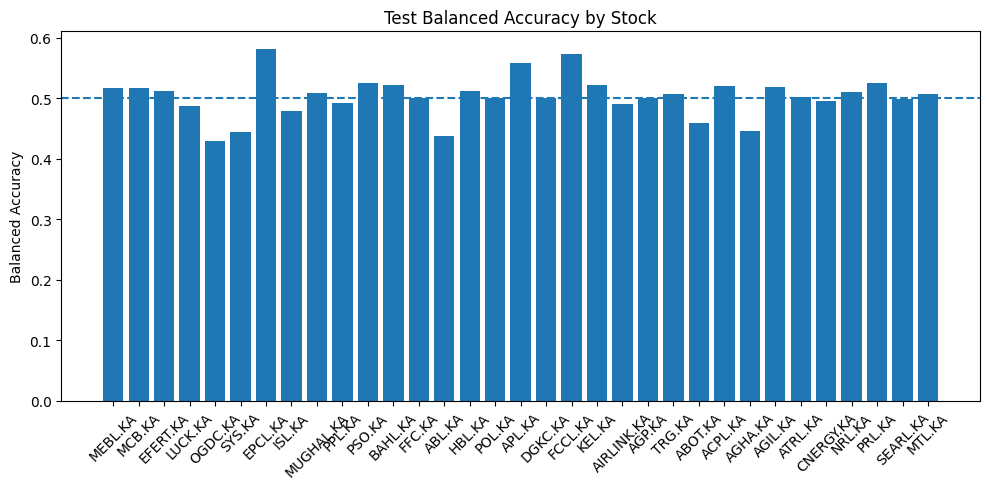

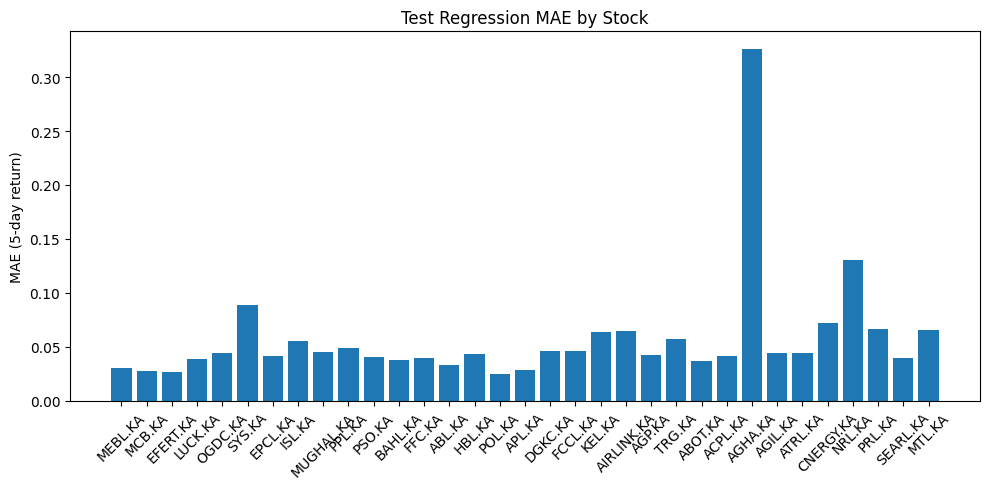

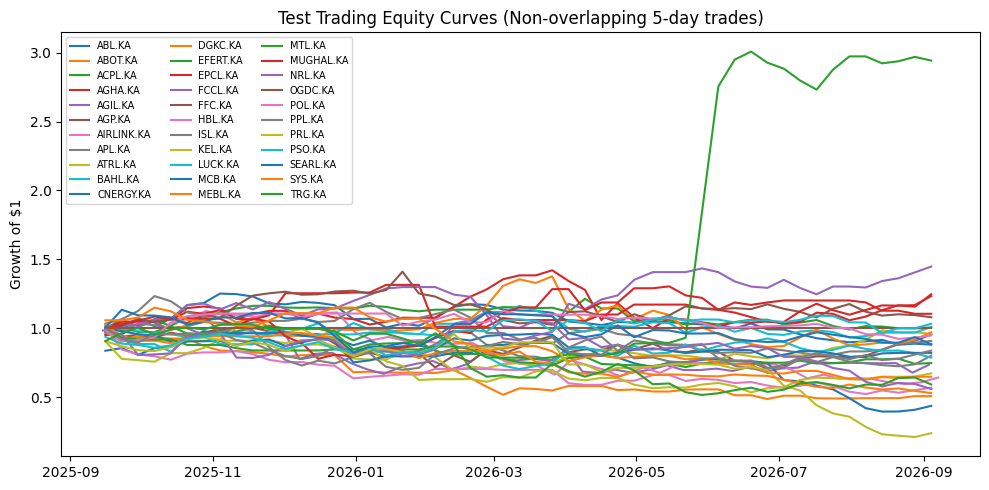

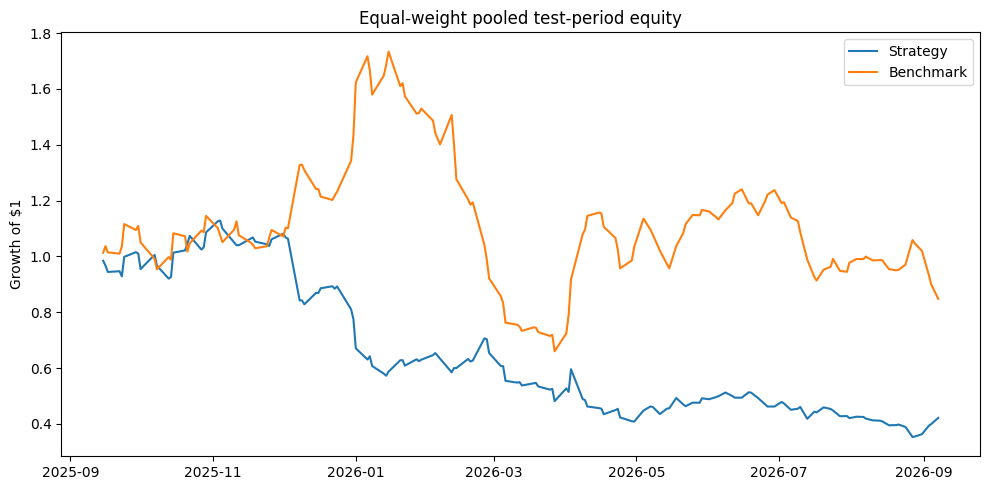

Saved: PSX_STAGE_1_DATA_QUALITY_COMPUTATIONAL_USABILITY_FINAL.xlsx
Download results and plots from Colab Files pane.


In [5]:
# =====================================================================
# MODELLING RESULTS, VISUALIZATION AND EXPORT
# =====================================================================
classification_df=pd.DataFrame(class_rows); regression_df=pd.DataFrame(reg_rows)
# Validation comparison and selected-model test results
validation_class=classification_df[classification_df.Split=='Validation'].copy()
validation_reg=regression_df[regression_df.Split=='Validation'].copy()
summary_class=classification_df[classification_df.Split=='Test'].copy()
summary_reg=regression_df[regression_df.Split=='Test'].copy()

# Visualizations: stock-wise test classification and regression metrics
if len(summary_class):
    plt.figure(figsize=(10,5)); plt.bar(summary_class.Ticker,summary_class.BalancedAccuracy); plt.axhline(.5,ls='--'); plt.title('Test Balanced Accuracy by Stock'); plt.ylabel('Balanced Accuracy'); plt.xticks(rotation=45); plt.tight_layout(); plt.savefig('classification_test.png',dpi=160); plt.show()
if len(summary_reg):
    plt.figure(figsize=(10,5)); plt.bar(summary_reg.Ticker,summary_reg.MAE); plt.title('Test Regression MAE by Stock'); plt.ylabel('MAE (5-day return)'); plt.xticks(rotation=45); plt.tight_layout(); plt.savefig('regression_test_mae.png',dpi=160); plt.show()
if len(trade_detail_df):
    plt.figure(figsize=(10,5))
    for t,g in trade_detail_df.groupby('Ticker'):
        plt.plot(pd.to_datetime(g.Date),g.Equity,label=t)
    plt.title('Test Trading Equity Curves (Non-overlapping 5-day trades)'); plt.ylabel('Growth of $1'); plt.legend(fontsize=7,ncol=3); plt.tight_layout(); plt.savefig('trading_equity_curves.png',dpi=160); plt.show()

# Combined portfolio across stock-level trade sequences: stock-specific results
# remain primary; pooled statistics are a simple equal-weight aggregation by trade row.
if len(trade_detail_df):
    pooled=trade_detail_df.copy(); pooled['Period']=pd.to_datetime(pooled.Date)
    pooled_summary=pooled.groupby('Period')[['NetStrategyReturn','BenchmarkReturn']].mean().reset_index()
    pooled_summary['StrategyEquity']=(1+pooled_summary.NetStrategyReturn).cumprod()
    pooled_summary['BenchmarkEquity']=(1+pooled_summary.BenchmarkReturn).cumprod()
    plt.figure(figsize=(10,5)); plt.plot(pooled_summary.Period,pooled_summary.StrategyEquity,label='Strategy'); plt.plot(pooled_summary.Period,pooled_summary.BenchmarkEquity,label='Benchmark'); plt.title('Equal-weight pooled test-period equity'); plt.ylabel('Growth of $1'); plt.legend(); plt.tight_layout(); plt.savefig('pooled_equity.png',dpi=160); plt.show()

OUT='PSX_STAGE_1_DATA_QUALITY_COMPUTATIONAL_USABILITY_FINAL.xlsx'
with pd.ExcelWriter(OUT,engine='openpyxl') as w:
    pd.DataFrame({'SelectedFeature':model_features}).to_excel(w,index=False,sheet_name='Model_Features')
    status_df.to_excel(w,index=False,sheet_name='TrainFeatureScreen')
    classification_df.to_excel(w,index=False,sheet_name='Classification')
    regression_df.to_excel(w,index=False,sheet_name='Regression')
    trading_df.to_excel(w,index=False,sheet_name='TradingSummary')
    trade_detail_df.to_excel(w,index=False,sheet_name='TradeDetails')
    download_df.to_excel(w,index=False,sheet_name='Downloads')
    if len(pooled_summary): pooled_summary.to_excel(w,index=False,sheet_name='PooledEquity')
print('Saved:',OUT)
print('Download results and plots from Colab Files pane.')
